# Coral Reef One Health: maps, evidence and priorities

**Global health · 15–25 minutes · learning companion**

Connect three reef-mapping initiatives with field observations and community questions, then test how arbitrary weights and missing evidence change an original teaching index.

**Learning question:** Can changing a preference change an ordering without changing a single observation?

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/evidence-to-action.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Reef mapping describes spatial patterns; field surveys can test habitat interpretations. A One Health question also needs a defined outcome and locally agreed evidence about people, animals and ecosystems. A habitat class is not a health measurement.

This original fixture uses two **invented normalized descriptors** in arbitrary 0–1 units: a habitat descriptor and a field descriptor. Larger means only a larger authored number; neither has a validated favorable direction. Sites A, B and C have no real locations or communities. No source-course CSV or provider measurements enter this activity.

Predict A and B under positive weights 3:1. Normalize each weight by their total, then add descriptor × normalized weight. C is missing the field descriptor (`None`), so its index stays unknown. Its observed weight coverage is the sum of normalized weights for available descriptors: 75% under 3:1. Coverage measures completeness under the chosen weights, not accuracy, confidence or survey representativeness. Never divide by only the observed weights or fill the gap with zero.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Invented inputs: {'A': (0.8, 0.2), 'B': (0.2, 0.8), 'C': (0.9, None)}
Descriptor order: ('habitat descriptor', 'field descriptor') ; weights: (3.0, 1.0)
Units: arbitrary normalized 0–1; larger means a larger invented descriptor, not better health.
A: teaching index 0.650; observed weight coverage 100%; 2/2 descriptors
B: teaching index 0.350; observed weight coverage 100%; 2/2 descriptors
C: teaching index unknown; observed weight coverage 75%; 1/2 descriptors
Complete-evidence ordering (largest first): ['A', 'B']
Weights change an assumption, not the observations. This is not a validated health or conservation index.


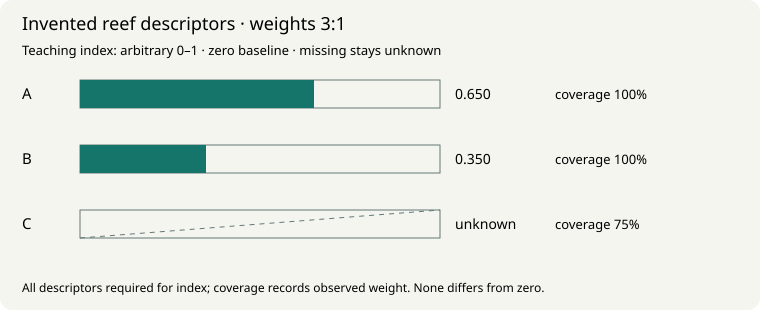

In [2]:
from math import isfinite

# Fictional sites: arbitrary normalized descriptors, not measured reef health.
indicator_names = ('habitat descriptor', 'field descriptor')
sites = {'A': (0.8, 0.2), 'B': (0.2, 0.8), 'C': (0.9, None)}
weights = (3.0, 1.0)

def teaching_index(values, weights):
    """Require complete evidence; report observed weight coverage separately."""
    if not weights or len(values) != len(weights):
        raise ValueError('Supply one positive finite weight per descriptor.')
    if any(isinstance(w, bool) or not isinstance(w, (int, float))
           or not isfinite(w) or w <= 0 for w in weights):
        raise ValueError('Every weight must be a positive finite number.')
    if any(v is not None and (isinstance(v, bool) or not isinstance(v, (int, float))
           or not isfinite(v) or not 0 <= v <= 1) for v in values):
        raise ValueError('Descriptors must be finite numbers from 0 to 1, or None.')
    # Scale before summing so even very large finite weights can be normalized.
    scaled = [w / max(weights) for w in weights]
    normalized = [w / sum(scaled) for w in scaled]
    observed = sum(v is not None for v in values)
    coverage = sum(w for v, w in zip(values, normalized) if v is not None)
    score = sum(v * w for v, w in zip(values, normalized)) if observed == len(values) else None
    return {'index': score, 'coverage': coverage, 'observed': observed}

def coverage_label(result):
    """Keep incomplete evidence distinct from both coverage endpoints."""
    if result['observed'] == 0:
        return '0%'
    if result['index'] is not None:
        return '100%'
    rounded = round(100 * result['coverage'])
    return '<100%' if rounded == 100 else '>0%' if rounded == 0 else f"{result['coverage']:.0%}"

results = {name: teaching_index(values, weights) for name, values in sites.items()}
weight_label = ':'.join(f'{w:g}' for w in weights)
print('Invented inputs:', sites)
print('Descriptor order:', indicator_names, '; weights:', weights)
print('Units: arbitrary normalized 0–1; larger means a larger invented descriptor, not better health.')
for name, result in results.items():
    value = 'unknown' if result['index'] is None else f"{result['index']:.3f}"
    print(f"{name}: teaching index {value}; observed weight coverage {coverage_label(result)}; "
          f"{result['observed']}/{len(weights)} descriptors")
complete = {name: r['index'] for name, r in results.items() if r['index'] is not None}
print('Complete-evidence ordering (largest first):', sorted(complete, key=complete.get, reverse=True))
print('Weights change an assumption, not the observations. This is not a validated health or conservation index.')

title = f'Invented reef descriptors · weights {weight_label}'
height = max(260, 115 + len(results) * 65)
body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
body += '<text x="22" y="55" font-family="sans-serif" font-size="13">Teaching index: arbitrary 0–1 · zero baseline · missing stays unknown</text>'
for i, (name, result) in enumerate(results.items()):
    y = 80 + i * 65
    body += f'<text x="22" y="{y+19}" font-family="sans-serif" font-size="15">{escape(name)}</text>'
    body += f'<rect x="80" y="{y}" width="360" height="28" fill="none" stroke="#637778"/>'
    value = result['index']
    if value is None:
        label = 'unknown'
        body += f'<path d="M80 {y+28}L440 {y}" stroke="#637778" stroke-dasharray="5 5"/>'
    else:
        label = f'{value:.3f}'
        body += f'<rect x="80" y="{y}" width="{360*value:.2f}" height="28" fill="#16756b"/>'
    body += f'<text x="455" y="{y+19}" font-family="sans-serif" font-size="14">{label}</text>'
    body += f'<text x="555" y="{y+19}" font-family="sans-serif" font-size="13">coverage {escape(coverage_label(result))}</text>'
body += f'<text x="22" y="{height-18}" font-family="sans-serif" font-size="12">All descriptors required for index; coverage records observed weight. None differs from zero.</text>'
description = '; '.join(f"{name}: index {r['index']}, observed weight coverage {coverage_label(r)}" for name, r in results.items())
svg(body, title, description, height=height)


## Interpret the result

Under the defaults, A = **0.650** and B = **0.350**, while C remains **unknown**, with 75% observed weight coverage and one of two descriptors. A comes first only under the chosen arbitrary direction and preferences. A complete pair does not establish valid measurement, agreement across scales, or a justified decision. The SVG shows unknown explicitly rather than plotting it as zero.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Change `weights = (3.0, 1.0)` to `(1.0, 3.0)` and rerun the analysis cell. Predict A = **0.350**, B = **0.650**, a reversed ordering, and C coverage = **25%** with its index still unknown. The printed results and SVG must change together; no new observations were made.

Restore weights 3:1, then replace C's `None` with numeric `0`. C becomes **0.675** with 100% coverage: zero is observed, not missing. Next replace C's pair with `(None, None)`: its index stays unknown and coverage is 0%. Restore the default before saving. Try a zero, negative, infinite or NaN weight: a clear `ValueError` must stop the calculation before normalization.

Choose a community-defined question about reef use or livelihoods and write an evidence plan: who frames the question; outcome and units; imagery and survey dates; class definitions; spatial support; missing observations; consent/access; validation; and who can challenge the interpretation. This exercise selects no real intervention or conservation priority.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Reef mapping: what can be compared?

| Initiative | Evidence contribution | Check before comparison |
|---|---|---|
| [Allen Coral Atlas](https://allencoralatlas.org/) | Broad shallow tropical habitat maps and monitoring | Product version, imagery dates, depth/visibility, class definitions and validation; a habitat class is not measured live coral cover. |
| [KSLOF Global Reef Expedition](https://www.livingoceansfoundation.org/mapping-the-worlds-coral-reefs/) / [World Reef Map](https://maps.lof.org/) | Satellite habitat/bathymetry maps supported by field observations | Expedition sampling, dates, geographic extent and data-request permissions; selected coverage is not a global time series. |
| [NASA/USF Millennium mapping](https://landsat.gsfc.nasa.gov/wp-content/uploads/2012/07/coral-l7.pdf) | Historical Landsat baseline using 1999–2002 imagery | Historical resolution and observation period; a modern compilation release does not make the underlying observations current. |

Class labels, pixel size, reef zone, depth, survey method and observation period need compatible meanings before combining products. A finer display zoom does not create finer measurements. Missing mapped habitat or a missing survey is not evidence of absent reefs. Read product metadata and record uncertainty before any comparison.

## From a map to a One Health question

Use [WHO's One Health framing](https://www.who.int/health-topics/one-health) to connect ecosystem, animal and human questions, with affected communities helping define outcomes and authority. [Sweet, Burian and Bulling (2021)](https://doi.org/10.1016/j.jip.2021.107538) motivate marine inclusion; their indexed abstract also identifies challenges in linking reef monitoring with ecosystem services. [NOAA's ecosystem overview](https://www.noaa.gov/education/resource-collections/marine-life/coral-reef-ecosystems) supplies context, not evidence for an individual health claim.

| Question | What spatial evidence contributes | What remains to measure or agree |
|---|---|---|
| Are habitat patterns comparable over time? | Dated classes and mapped support | Comparable methods, field validation and missing-coverage accounting. |
| How might reef change relate to food or livelihoods? | Environmental context for a hypothesis | Fishery observations and consented, community-led research on the defined outcome. |
| Which action deserves a locally chosen trial? | A place to discuss evidence gaps | Community priorities, governance, feasibility, uncertainty and a review/stopping rule. |

This is an original evidence chain, not a causal model. Maps cannot diagnose disease, establish seafood safety or carbon balance, or determine real community wellbeing. A weighted descriptor cannot turn those gaps into observations.

## Two source notebooks and four research continuations

These exact Lab URLs are documented in the reviewed source material; pinned files preserve the inspected version. The source runtime and rights are separate from this atlas. Entry HTTP 200 on 2026-11-02 certifies neither the notebook query target nor execution.

| Source notebook | Exact source Lab | Inspected file |
|---|---|---|
| Mapping catalogue | [Run mapping](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/lite/lab/index.html?path=01-reef-mapping.ipynb) | [Pinned mapping notebook](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/content/01-reef-mapping.ipynb) |
| Synthetic One Health indicators | [Run One Health](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/lite/lab/index.html?path=02-one-health.ipynb) | [Pinned One Health notebook](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/content/02-one-health.ipynb) |

The [luismmontilla and contributors discovery directory](https://github.com/luismmontilla/awesome-coral-research) helped select these separate services:

| Tool | Evidence question for a continuation |
|---|---|
| [NOAA Coral Reef Watch](https://coralreefwatch.noaa.gov/satellite/index.php) | Compare a dated heat-stress product's scale with field observations; an alert is not observed bleaching everywhere. |
| [MERMAID / WCS](https://datamermaid.org/) | Specify fish/benthic survey methods, dates, effort and permissions before comparing sites. |
| [CoralNet](https://coralnet.ucsd.edu/) | Define image labels and independent agreement/validation before interpreting annotations. |
| [OBIS / IOC-UNESCO](https://obis.org/) | Inspect dates, taxonomy, locations and sampling effort; no record does not mean absence. |

Nothing is downloaded or installed here. A real-data continuation needs provider metadata, citations and terms, comparable observations and locally agreed permissions before analysis. Connect this question with [Earth-observation cubes](../zarr-sql-views/index.ipynb), [Ocean Watch](../global-fishing-watch-and-dark-vessels/index.ipynb) and [global-health priorities](../rewiring-global-health/index.ipynb).

## Coral Reef One Health: citations and rights (2026-11-02)

- **Tobias, James L. / jltobias (2026).** *Coral Reef One Health*. [Reviewed README](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/README.md), commit `6b76d79a9b4b683a52bbf0ba019f204e7635aaf9`, inspected 2026-11-02. [Mapping guide](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/book/mapping-initiatives.md), [One Health guide](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/book/one-health.md), [research guide](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/book/research-resources.md) and [source references](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/book/references.md) informed the selection. **No repository-wide license selected**: no source code, dataset, prose, artwork or splash is copied.
- **Allen Coral Atlas / Arizona State University Center for Global Discovery and Conservation Science and partners.** [Atlas](https://allencoralatlas.org/), [methods](https://allencoralatlas.org/methods/) and [Terms of Use](https://allencoralatlas.org/tou/). Credit Paul Allen's Vulcan, Planet, Coral Reef Alliance and University of Queensland. Shallow habitat classes depend on product, depth and water visibility; they are not direct live coral cover or household health. Website terms and product permissions are separate; no blanket CC BY grant is asserted.
- **Khaled bin Sultan Living Oceans Foundation (KSLOF).** [Mapping the World's Coral Reefs](https://www.livingoceansfoundation.org/mapping-the-worlds-coral-reefs/) and [World Reef Map](https://maps.lof.org/). Expedition habitat/bathymetry mapping combines satellite and field evidence, with NASA collaboration; selected sites are not continuous global monitoring. Viewing and the provider's data-request permissions are separate.
- **NASA Landsat / University of South Florida Institute for Marine Remote Sensing (IMaRS).** [*Landsat 7 Worldwide Inventory of Coral Reefs Completed*](https://landsat.gsfc.nasa.gov/wp-content/uploads/2012/07/coral-l7.pdf), historical Millennium mapping context using 1999–2002 imagery. [IMaRS project](https://imars.usf.edu/millennium-corals/) and [UNEP-WCMC global reef compilation record](https://data-gis.unep-wcmc.org/portal/home/item.html?id=0613604367334836863f5c0c10e452bf) are continuation links: obtain the actual product version, contributors, requested citation and terms from current provider metadata. A release date is not every feature's observation date.
- **World Health Organization.** [One Health](https://www.who.int/health-topics/one-health), for integrated people/animal/ecosystem inquiry and shared governance. **Sweet, Michael; Burian, Alfred; Bulling, Mark (2021).** *Corals as canaries in the coalmine: Towards the incorporation of marine ecosystems into the 'One Health' concept*. Journal of Invertebrate Pathology **186**, 107538. [DOI](https://doi.org/10.1016/j.jip.2021.107538) · [PubMed PMID 33545133](https://pubmed.ncbi.nlm.nih.gov/33545133/). Indexed abstract and bibliographic metadata inspected; full text not inspected. The arbitrary atlas index does not implement or validate their proposed framework.
- **NOAA.** [Coral reef ecosystems](https://www.noaa.gov/education/resource-collections/marine-life/coral-reef-ecosystems), ecosystem-services and cultural context; no photographs or clinical findings copied. The evidence plan here is an original interpretation, not a reproduced WHO or NOAA diagram.
- **luismmontilla and contributors.** [Awesome coral research](https://github.com/luismmontilla/awesome-coral-research), discovery directory, [CC BY 4.0 license](https://github.com/luismmontilla/awesome-coral-research/blob/master/LICENCE.md). Credit the directory's selection; this atlas selects four links with newly authored descriptions and copies no full directory or image. Provider terms remain separate.
- **NOAA Coral Reef Watch.** [Satellite monitoring/products](https://coralreefwatch.noaa.gov/satellite/index.php): temperature, heat stress and bleaching alerts are distinct from field bleaching observations. **MERMAID team / Wildlife Conservation Society.** [MERMAID](https://datamermaid.org/): standardized field survey collection, exploration and management. **CoralNet team.** [CoralNet](https://coralnet.ucsd.edu/): image organization/annotation and statistics, with labels requiring validation. **OBIS contributors / IOC-UNESCO.** [Ocean Biodiversity Information System](https://obis.org/): marine occurrence discovery; sampling effort matters and absent records do not establish species absence. Obtain dataset-specific citations, versions, permissions and access conditions from each provider before any continuation.

Only the sources used above are cited as consulted; unused source-course readings and videos are not adopted. No provider data, reef/community observations, imagery, annotations, models or API connections are bundled or requested. All summaries, fixture code and SVGs here are original: **MIT code; CC BY 4.0 narrative, figures and synthetic fixtures**, attributed to James L. Tobias and contributors (2026). External rights remain with their creators; no endorsement is implied. The 2026-11-02 HTTP checks establish entry reachability only, not external notebook targets or service functions.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Coral-Reef-One-Health](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Coral-Reef-One-Health/blob/6b76d79a9b4b683a52bbf0ba019f204e7635aaf9/README.md); inspected 2026-11-02, commit `6b76d79a9b4b`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

No repository-wide source license has been selected. The source is linked without copying its code, CSV, prose or splash illustration. The local fixture and SVG are original; executable code is MIT and original narrative/figures/fixtures are CC BY 4.0. Maps and this score establish neither disease, seafood safety, causality, carbon balance nor real community outcomes.

- [Open Coral learning hub](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/) — Source portal linking the separate Book and Lab. **HTTP 200 - entry only**
- [Read source Coral Book](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/book/) — Source reef mapping, One Health and research-tool explanations. **HTTP 200 - entry only**
- [Run source Coral Lab](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/lite/lab/index.html) — Separate source browser runtime; its own terms and dependencies apply. **HTTP 200 - entry only**
- [Run source mapping notebook](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/lite/lab/index.html?path=01-reef-mapping.ipynb) — Exact documented mapping-catalogue notebook entry; target execution not certified. **HTTP 200 - entry only**
- [Run source One Health notebook](https://jltobias.github.io/JupyterLite-Coral-Reef-One-Health/lite/lab/index.html?path=02-one-health.ipynb) — Exact source synthetic-indicator notebook entry; target execution not certified. **HTTP 200 - entry only**
- [Explore Allen Coral Atlas](https://allencoralatlas.org/) — External shallow reef habitat mapping; check product dates, classes and terms. **HTTP 200 - entry only**
- [Explore KSLOF World Reef Map](https://maps.lof.org/) — External expedition habitat and bathymetry viewer; viewing does not grant data reuse. **HTTP 200 - entry only**
- [Explore NOAA Coral Reef Watch](https://coralreefwatch.noaa.gov/satellite/index.php) — External satellite heat-stress and bleaching-alert products; not field observations everywhere. **HTTP 200 - entry only**
- [Explore MERMAID surveys](https://datamermaid.org/) — External WCS/MERMAID field-survey collection, exploration and management. **HTTP 200 - entry only**
- [Explore CoralNet annotations](https://coralnet.ucsd.edu/) — External reef-image annotation service; labels need independent validation. **HTTP 200 - entry only**
- [Explore OBIS occurrences](https://obis.org/) — External marine biodiversity discovery; sampling effort and provider terms matter. **HTTP 200 - entry only**

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For a continuation, inspect each provider's product metadata, version, observation dates, requested citation and permissions; source entry checks do not validate service functions. The original local exercise uses only standard-library Python and IPython display.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
